> **This notebook needs an Arraylake account.** It reads the Arraylake repository
> `earthmover-demos/xenium-virtual-bundle`, and Arraylake has no anonymous read. The committed
> run addressed 1.33 GB of published 10x files with 313 element references. It copied 14.0 MB
> of that, which is 1.05%. The outputs below ship executed. A reader without an account sees
> every value this run produced.

# A 10x Xenium bundle from Arraylake, without a copy of it

`earthmover-demos/xenium-virtual-bundle` is an Arraylake repo for a 10x Xenium breast cancer run.
The run has transcripts, a morphology image, cell and nucleus boundaries, and an expression
matrix. The repo contains almost none of these bytes. Every file stays where 10x published it, in
the public 10x bucket `10x.files`. The repo holds byte ranges into the files.

This notebook is the read side. The build side needs an Arraylake account, so its script stays
outside this repository. The design and its constraints are in
[`../icechunk-SpatialData/README.md`](../icechunk-SpatialData/README.md).

Most of this notebook looks like ordinary data access. Only the byte counters show how little
the repo copied.

## Open the repo

Nothing here is specific to virtual data. `get_repo` returns an Icechunk repository. A read-only
session returns a store. Zarr opens that store. The repository config only adds retries to the
reads. `bounded_reads` only limits their connections.

The one thing to notice is `authorized_virtual_container_prefixes`. It shows that Arraylake vends
credentials for references under `s3://samples/`. Without it, this repo opens and then fails on
the first read. In fact, `get_repo` itself returns HTTP 400.

In [1]:
import warnings

warnings.simplefilter("ignore")

import numpy as np
import zarr
from arraylake import Client
from arraylake import config as al_config

import icechunk_spatialdata as isd

# The published repo is on prod. A local config can point the client at dev.
al_config.set({"service.uri": "https://api.earthmover.io"})

REPO = "earthmover-demos/xenium-virtual-bundle"

# The config adds retries. bounded_reads limits connections. The data path does not change.
repo = Client().get_repo(REPO, config=isd.repository_config())
isd.bounded_reads()
session = repo.readonly_session("main")
root = zarr.open_group(session.store, mode="r")

print(f"{REPO}")
print(f"  authorized virtual prefixes: {sorted(repo.authorized_virtual_container_prefixes)}")
print(f"  top level: {sorted(root.keys())}")

earthmover-demos/xenium-virtual-bundle
  authorized virtual prefixes: ['s3://10x.files/']
  top level: ['files', 'images', 'shapes']


## What the repo actually stores

`files/` holds one `uint8` array per published file. Each array has the file's exact length. A
`uint8` Zarr array has no codec, so a chunk of it *is* a byte range. Thus Icechunk can reference
an arbitrary file, whatever its format.

`chunk_type` tells you, per chunk, where the bytes are. Below, every chunk is `Virtual` except the
last. The build copied the last chunk. A Zarr chunk has a fixed size, and a byte range cannot pad.

In [2]:
files = {name: array for name, array in root["files"].arrays()}

total = 0
copied = 0
file_references = 0
print(f"{'file':<32} {'size':>10}  {'chunks':>7}  {'virtual':>8}  {'copied':>8}")
for name, array in sorted(files.items(), key=lambda kv: -kv[1].shape[0]):
    n_chunks = -(-array.shape[0] // array.chunks[0])
    kinds = [str(session.chunk_type(f"/files/{name}", [i])) for i in range(n_chunks)]
    virtual = sum(k == "ChunkType.virtual" for k in kinds)
    tail = array.shape[0] - (n_chunks - 1) * array.chunks[0]
    total += array.shape[0]
    copied += tail
    file_references += virtual
    print(f"{name:<32} {array.shape[0] / 1e6:>7.1f} MB  {n_chunks:>7}  "
          f"{virtual:>8}  {tail / 1e6:>5.1f} MB")

everything = len(session.all_virtual_chunk_locations())
print(f"\n{total / 1e9:.2f} GB addressed by {file_references:,} references, "
      f"{copied / 1e6:.1f} MB of it copied ({copied / total:.2%}) — the tails, nothing else")
print(f"the repo holds {everything:,} references in all; the other "
      f"{everything - file_references:,} address one of these files a second way, as the image "
      f"element further down")

file                                   size   chunks   virtual    copied
transcripts.parquet                669.8 MB      160       159    2.9 MB


morphology_mip.ome.tif             627.8 MB      150       149    2.9 MB
cell_feature_matrix.h5              12.1 MB        3         2    3.8 MB
cell_boundaries.parquet              8.8 MB        3         2    0.4 MB
nucleus_boundaries.parquet           8.3 MB        2         1    4.1 MB



1.33 GB addressed by 313 references, 14.0 MB of it copied (1.05%) — the tails, nothing else
the repo holds 2,787 references in all; the other 2,474 address one of these files a second way, as the image element further down


### Where the bytes come from

The locations are ordinary `s3://` URLs into `10x.files`, a bucket that 10x owns. The bucket is
public, and anonymous reads work. Arraylake authorizes a virtual container through a map from a
URL prefix to a *bucket config*. Here a real bucket exists for that config.

In [3]:
import collections

locations = collections.Counter(session.all_virtual_chunk_locations())
for location, references in sorted(locations.items()):
    print(f"{references:>4} refs  {location}")

print("\n... each of which is served, byte for byte, over HTTPS from:")
print(min(locations).replace("s3://10x.files/", "https://s3-us-west-2.amazonaws.com/10x.files/"))

   2 refs  s3://10x.files/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_cell_boundaries.parquet
   2 refs  s3://10x.files/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_cell_feature_matrix.h5
2623 refs  s3://10x.files/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_morphology_mip.ome.tif
   1 refs  s3://10x.files/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_nucleus_boundaries.parquet
 159 refs  s3://10x.files/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_transcripts.parquet

... each of which is served, byte for byte, over HTTPS from:
https://s3-us-west-2.amazonaws.com/10x.files/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_cell_boundaries.parquet


## 42.6 million transcripts, and the 0.01% needed to describe them

`files/transcripts.parquet` is 670 MB. Its schema and row-group layout need only the footer and a
little more. An fsspec filesystem reaches each file inside the store. Thus
`pyarrow.parquet.ParquetFile` does its usual work.

The byte counter on the handle is the only unusual line in this cell.

In [4]:
import pyarrow.parquet as pq
from icechunk_spatialdata._filesystem import ZarrArrayFileSystem

filesystem = ZarrArrayFileSystem(root)
size = files["transcripts.parquet"].shape[0]

with filesystem.open("files/transcripts.parquet", "rb") as handle:
    parquet = pq.ParquetFile(handle)
    schema = parquet.schema_arrow
    metadata = parquet.metadata
    groups = [metadata.row_group(i).num_rows for i in range(metadata.num_row_groups)]

    # The footer also holds per-row-group min/max for every column.
    # Thus the same bytes give the position of each row group on the slide.
    columns = [metadata.schema.column(i).name for i in range(metadata.num_columns)]
    x_column, y_column = columns.index("x_location"), columns.index("y_location")
    extents = [
        (metadata.row_group(i).column(x_column).statistics,
         metadata.row_group(i).column(y_column).statistics)
        for i in range(metadata.num_row_groups)
    ]
    footer_cost = handle.raw.bytes_read

    print(f"columns: {schema.names}")
    print(f"{sum(groups):,} transcripts in {len(groups)} row groups "
          f"(first: {groups[0]:,} rows)")
    print(f"read {footer_cost / 1e6:.2f} MB of {size / 1e6:.0f} MB "
          f"({footer_cost / size:.2%}) to learn all of that")

    # One row group, four columns. Parquet's layout makes these a few contiguous ranges.
    # Thus the read is a few ranged GETs.
    before = handle.raw.bytes_read
    batch = parquet.read_row_group(
        0, columns=["x_location", "y_location", "feature_name", "qv"]
    )
    group_cost = handle.raw.bytes_read - before

transcripts = batch.to_pandas()
transcripts["feature_name"] = transcripts["feature_name"].str.decode("utf-8")
print(f"\nrow group 0: {len(transcripts):,} rows x 4 columns for "
      f"{group_cost / 1e6:.1f} MB ({group_cost / size:.2%})")
print(transcripts.head(3).to_string())

columns: ['transcript_id', 'cell_id', 'overlaps_nucleus', 'feature_name', 'x_location', 'y_location', 'z_location', 'qv']
42,638,083 transcripts in 43 row groups (first: 1,000,000 rows)
read 0.07 MB of 670 MB (0.01%) to learn all of that



row group 0: 1,000,000 rows x 4 columns for 9.6 MB (1.44%)
   x_location  y_location             feature_name         qv
0    4.395842  328.666473                   SEC11C  18.662479
1    5.074415  236.964844  NegControlCodeword_0502  18.634956
2    4.702023  322.797150                   SEC11C  18.662479


Those 65 KB gave more than a schema. Parquet footers hold per-row-group min/max for every
column. Thus the same read gives the position of each row group on the slide. That is a spatial
index at no extra cost.

The index is coarse. The figure below shows the limit. The 43 footprints form clean bands in
`y`. Each one spans almost the full width in `x`. Thus the footer prunes a `y`-range query. It
does nothing at all for an `x`-range query. The figure draws the transcripts of row group 0 on
top. They fall in two disjoint patches inside their band. The rows have enough order to form
bands, but no order within a band. Thus the pruning to a few ranged GETs works here along one
axis only.

After that, the cell uses ordinary pandas on the row group that it already read.

492 genes, 83.1% of transcripts pass Q20


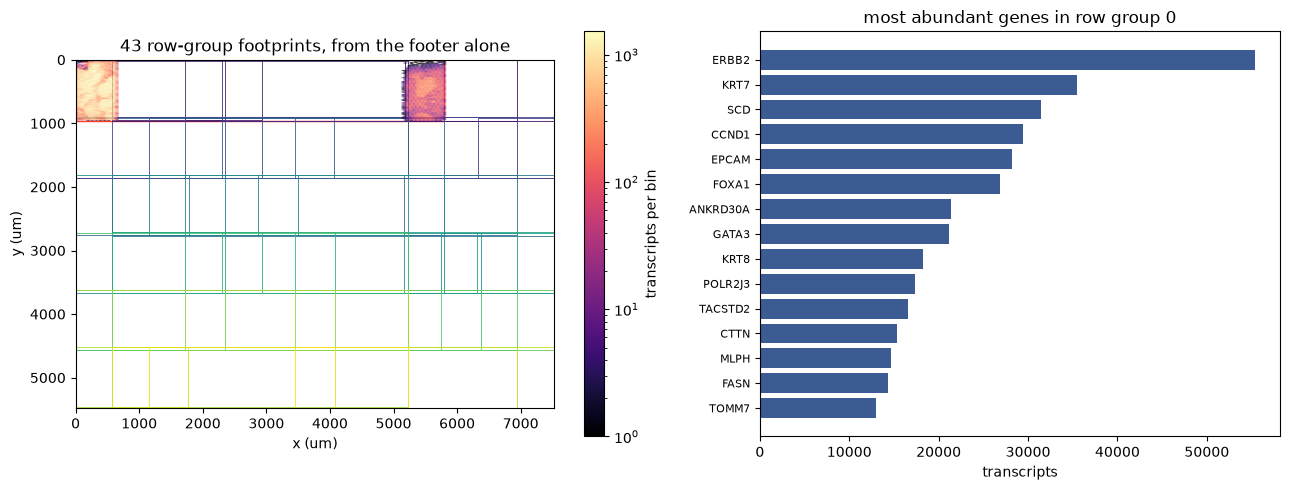

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

confident = transcripts[transcripts["qv"] >= 20]
counts = confident["feature_name"].value_counts()

figure, axes = plt.subplots(1, 2, figsize=(13, 5),
                            gridspec_kw={"width_ratios": [1.15, 1]})

# Draw the footprint of each row group from the footer statistics.
for index, (x_statistics, y_statistics) in enumerate(extents):
    axes[0].add_patch(Rectangle(
        (x_statistics.min, y_statistics.min),
        x_statistics.max - x_statistics.min, y_statistics.max - y_statistics.min,
        fill=False, linewidth=1.0 if index == 0 else 0.6,
        edgecolor="#ff3b30" if index == 0 else plt.cm.viridis(index / len(extents)),
    ))

hexbin = axes[0].hexbin(confident["x_location"], confident["y_location"],
                        gridsize=90, cmap="magma", bins="log", linewidths=0)
axes[0].set(xlabel="x (um)", ylabel="y (um)",
            title=f"{len(groups)} row-group footprints, from the footer alone")
axes[0].set_aspect("equal")
axes[0].set_xlim(0, 7526)
axes[0].set_ylim(5478, 0)
figure.colorbar(hexbin, ax=axes[0], label="transcripts per bin")

top = counts.head(15)[::-1]
axes[1].barh(top.index, top.values, color="#3b5b92")
axes[1].set(xlabel="transcripts", title="most abundant genes in row group 0")
axes[1].tick_params(axis="y", labelsize=8)

figure.tight_layout()
print(f"{confident['feature_name'].nunique()} genes, "
      f"{len(confident) / len(transcripts):.1%} of transcripts pass Q20")

## The morphology image, one pyramid level at a time

`morphology_mip.ome.tif` is 628 MB of tiled JPEG 2000 in eight pyramid levels. `tifffile` opens
it through the same filesystem. It reads the OME-TIFF structure first, then the requested pyramid
level, and nothing else.

The repo holds this image **twice**. The first way is as file bytes. This way needs no extra
installation. Any OME-TIFF reader can read this, because it *is* the OME-TIFF. The second way
comes after the boundaries. Each way is good at different tasks.

In [6]:
import tifffile

size = files["morphology_mip.ome.tif"].shape[0]

with filesystem.open("files/morphology_mip.ome.tif", "rb") as handle:
    with tifffile.TiffFile(handle) as tif:
        series = tif.series[0]
        structure_cost = handle.raw.bytes_read
        print(f"{len(series.levels)} pyramid levels, level 0 is {series.shape}, "
              f"tiles of {tif.pages[0].tilelength}x{tif.pages[0].tilewidth}, "
              f"{tif.pages[0].compression.name}")
        print(f"  structure read for {structure_cost / 1e6:.2f} MB ({structure_cost / size:.2%})")

        before = handle.raw.bytes_read
        overview = series.levels[5].asarray()
        overview_cost = handle.raw.bytes_read - before

        before = handle.raw.bytes_read
        detail = series.levels[2].asarray()
        detail_cost = handle.raw.bytes_read - before

# Read the run's experiment.xenium from the store attributes, not from a copy in this cell.
# 10x publishes that file beside the bundle. Its `pixel_size` is the unit of level 0.
experiment = dict(root.attrs)["experiment_xenium"]["contents"]
MICRONS_PER_PIXEL = experiment["pixel_size"]
print(f"  pixel_size {MICRONS_PER_PIXEL} um, from {experiment['analysis_sw_version']} "
      f"on {experiment['instrument_sn']}")
overview_scale = MICRONS_PER_PIXEL * series.shape[1] / overview.shape[1]
detail_scale = MICRONS_PER_PIXEL * series.shape[1] / detail.shape[1]

print(f"  level 5 {overview.shape} at {overview_scale:.2f} um/px "
      f"for {overview_cost / 1e6:.2f} MB ({overview_cost / size:.2%})")
print(f"  level 2 {detail.shape} at {detail_scale:.2f} um/px "
      f"for {detail_cost / 1e6:.1f} MB ({detail_cost / size:.1%})")

8 pyramid levels, level 0 is (25778, 35416), tiles of 1024x1024, JPEG2000
  structure read for 0.65 MB (0.10%)


  pixel_size 0.2125 um, from Xenium-1.0.1 on Xenium prototype instrument
  level 5 (805, 1106) at 6.80 um/px for 0.92 MB (0.15%)
  level 2 (6444, 8854) at 0.85 um/px for 34.3 MB (5.5%)


## The one element that is not a reference

`shapes/cell_boundaries` is a real SpatialData shapes element: 167,780 polygons. It uses
SpatialData's own on-disk format, and SpatialData's own writer wrote it. It is derived data. The
build made the polygons from the *referenced* vertex table, in the same transaction. Thus the
repo materializes it: 13 MB, against 1.33 GB addressed.

SpatialData's own reader needs one upstream change to read it back: the fsspec change in
[spatialdata#1107](https://github.com/scverse/spatialdata/pull/1107). Without it, geometry I/O
requires a filesystem path. Without that branch, the cell below reads the GeoParquet bytes
directly. That fallback works, but it skips the coordinate transformations.

In [7]:
import icechunk_spatialdata as isd

if isd.parquet_in_store_available():
    from spatialdata._io import io_shapes

    with isd.parquet_in_store():
        boundaries = io_shapes._read_shapes(root["shapes"]["cell_boundaries"])
    how = "SpatialData's own reader, through parquet_fs_fallback"
else:
    import geopandas as gpd

    with filesystem.open("shapes/cell_boundaries/shapes.parquet", "rb") as handle:
        boundaries = gpd.read_parquet(handle)
    how = "geopandas directly (no #1107: SpatialData's reader wants a path)"

print(f"read by {how}")
print(f"{len(boundaries):,} {boundaries.geometry.geom_type.iloc[0]}s")
print(f"  bounds (um): {np.round(boundaries.total_bounds, 1)}")
print(f"  image extent (um): "
      f"{np.round(np.array(series.shape[::-1]) * MICRONS_PER_PIXEL, 1)}")
print(f"  attrs: {sorted(boundaries.attrs)}")

read by SpatialData's own reader, through parquet_fs_fallback
167,780 Polygons
  bounds (um): [   0.     0.  7525.7 5477.6]
  image extent (um): [7525.9 5477.8]
  attrs: ['transform']


### Both halves together

The boundaries are in micrometres and the image is in pixels. One scale factor puts them in the
same frame. The bounds printed above agree to a pixel. This check shows that the two files really
do describe the same slide.

Left: the whole 7.5 x 5.5 mm section, from level 5. Right: 260 um of it from level 2, with cell
boundaries drawn on top. Both come from the same session. The repo copied neither file.

161 of 167,780 cells fall in the window


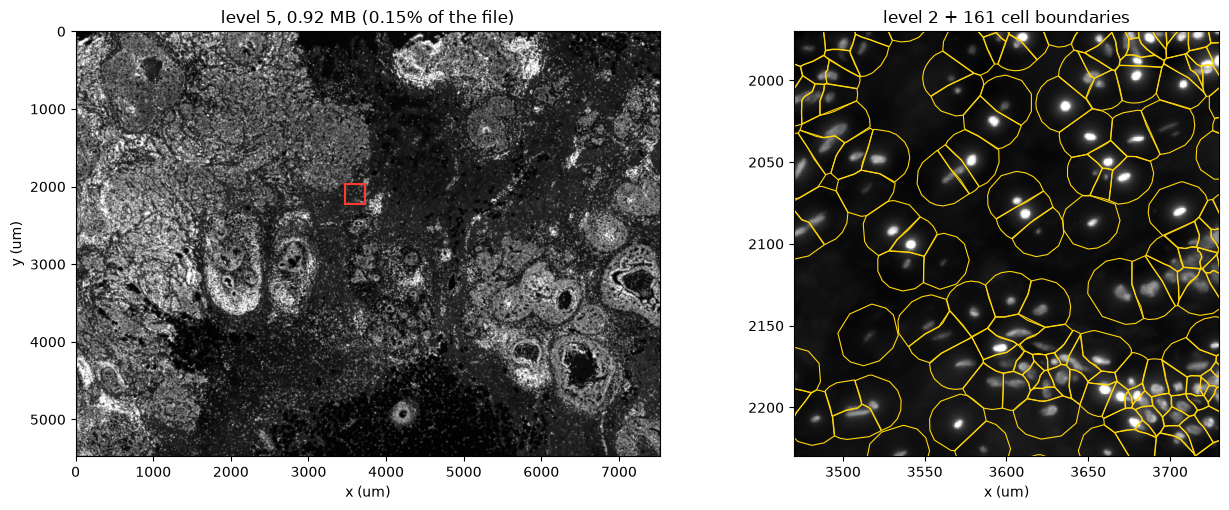

In [8]:
from matplotlib.patches import Rectangle

WINDOW = 260.0  # um
centre = np.array([3600.0, 2100.0])  # um, a dense region of the section
corner = centre - WINDOW / 2

figure, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

axes[0].imshow(overview, cmap="gray", vmax=np.percentile(overview, 99.5),
               extent=(0, overview.shape[1] * overview_scale,
                       overview.shape[0] * overview_scale, 0))
axes[0].add_patch(Rectangle(corner, WINDOW, WINDOW, fill=False, edgecolor="#ff3b30", lw=1.5))
axes[0].set(xlabel="x (um)", ylabel="y (um)",
            title=f"level 5, {overview_cost / 1e6:.2f} MB ({overview_cost / size:.2%} of the file)")

low = (corner / detail_scale).astype(int)
high = ((corner + WINDOW) / detail_scale).astype(int)
crop = detail[low[1]:high[1], low[0]:high[0]]
axes[1].imshow(crop, cmap="gray", vmax=np.percentile(crop, 99.5),
               extent=(corner[0], corner[0] + WINDOW, corner[1] + WINDOW, corner[1]))

window = boundaries.cx[corner[0]:corner[0] + WINDOW, corner[1]:corner[1] + WINDOW]
window.boundary.plot(ax=axes[1], color="#ffd60a", linewidth=0.8)
axes[1].set(xlim=(corner[0], corner[0] + WINDOW),
            ylim=(corner[1] + WINDOW, corner[1]),
            xlabel="x (um)",
            title=f"level 2 + {len(window):,} cell boundaries")

figure.tight_layout()
print(f"{len(window):,} of {len(boundaries):,} cells fall in the window")

### What this route cannot do

A request for a full-resolution *tile* is not cheap. `tifffile` can slice a pyramid level only
through its own Zarr view. zarr 3 cannot open a `ZarrTiffStore`, which is a v2-style mapping, not
a `Store`. Thus the only route is `asarray()`, which decodes the whole level. For level 0, that
is about 450 MB to see a 1024-pixel square.

The second representation exists for this case.

The TIFF parser that wrote the tile references also supplies their JPEG 2000 codec. Thus this
cell needs no extra installation.

In [9]:
import icechunk_spatialdata as isd


morphology = root["images"]["morphology_mip"]
levels = sorted(morphology.array_keys())

print(f"images/morphology_mip: {len(levels)} levels")
for level in levels:
    array = morphology[level]
    grid = tuple(-(-s // c) for s, c in zip(array.shape, array.chunks))
    print(f"  {level}  {str(array.shape):>22}  chunks {array.chunks}  "
          f"{int(np.prod(grid)):>4} tiles")

finest = morphology["s0"]
n_chunks = int(np.prod([-(-s // c) for s, c in zip(finest.shape, finest.chunks)]))
kinds = collections.Counter(
    str(session.chunk_type("/images/morphology_mip/s0", [0, row, column]))
    for row in range(-(-finest.shape[1] // finest.chunks[1]))
    for column in range(-(-finest.shape[2] // finest.chunks[2]))
)
print(f"\nlevel 0 chunk types: {dict(kinds)} — of {n_chunks}, none copied")
print(f"codec pipeline: {[type(codec).__name__ for codec in finest.metadata.codecs]}")

images/morphology_mip: 8 levels
  s0       (1, 25778, 35416)  chunks (1, 1024, 1024)   910 tiles
  s1       (1, 12889, 17708)  chunks (1, 1024, 1024)   234 tiles
  s2         (1, 6444, 8854)  chunks (1, 1024, 1024)    63 tiles
  s3         (1, 3222, 4427)  chunks (1, 1024, 1024)    20 tiles
  s4         (1, 1611, 2213)  chunks (1, 1024, 1024)     6 tiles
  s5          (1, 805, 1106)  chunks (1, 1024, 1024)     2 tiles
  s6           (1, 402, 553)  chunks (1, 1024, 1024)     1 tiles
  s7           (1, 201, 276)  chunks (1, 1024, 1024)     1 tiles

level 0 chunk types: {'ChunkType.virtual': 910} — of 910, none copied
codec pipeline: ['BytesCodec', 'Jpeg2KCodec']


The next cell does what the file route cannot do. One full-resolution tile is one chunk, so it is
one ranged GET and one decode. `tifffile` read its own per-tile byte counts with the structure
above. These counts give the exact size of that GET.

In [10]:
with filesystem.open("files/morphology_mip.ome.tif", "rb") as handle:
    with tifffile.TiffFile(handle) as tif:
        tile_bytes = tif.series[0].levels[0].pages[0].databytecounts

ROW, COLUMN = 4, 4          # a tile well inside the section
y0, x0 = ROW * 1024, COLUMN * 1024
tile = np.asarray(finest[0, y0:y0 + 1024, x0:x0 + 1024])
across = -(-finest.shape[2] // 1024)
cost = tile_bytes[ROW * across + COLUMN]

print(f"tile ({ROW}, {COLUMN}) at full resolution: {tile.shape} {tile.dtype}, "
      f"mean {tile.mean():.1f}")
print(f"  one chunk of {n_chunks}, {cost / 1e6:.2f} MB of the {size / 1e6:.0f} MB file "
      f"({cost / size:.3%})")
print(f"  the same pixels via tifffile's asarray: the whole of level 0, "
      f"{sum(tile_bytes) / 1e6:.0f} MB ({sum(tile_bytes) / size:.0%})")

tile (4, 4) at full resolution: (1024, 1024) uint16, mean 356.6
  one chunk of 910, 0.58 MB of the 628 MB file (0.092%)
  the same pixels via tifffile's asarray: the whole of level 0, 450 MB (72%)


### At full resolution, with the boundaries

The next figure draws the window from the overview figure twice. The left panel uses level 2
through the file. The right panel uses level 0 through the element. The nuclei are texture on the
left and objects on the right. The right-hand panel read a few tiles out of 910.

The element is also a real SpatialData image. The last cell below uses the prototype's reader to
rebuild it as a multiscale `Image2DModel`. The model has every pyramid level of the file, each
with its coordinate system.

4x the linear resolution, 6 of 910 level-0 chunks read


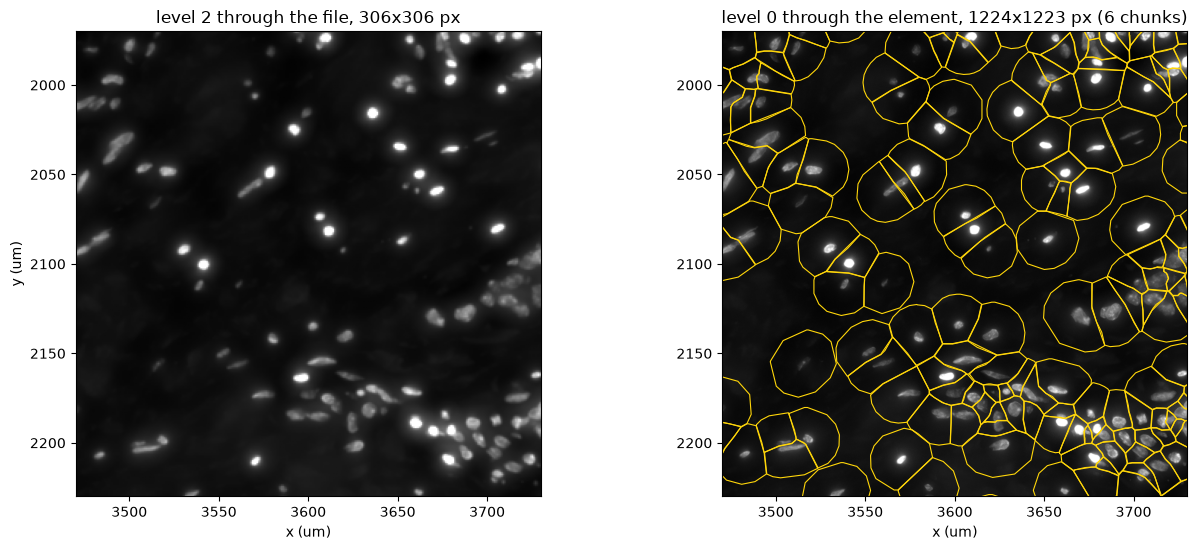

In [11]:
FULL_RES_PX = 1.0 / MICRONS_PER_PIXEL

figure, axes = plt.subplots(1, 2, figsize=(13.5, 5.6))

low = (corner / detail_scale).astype(int)
high = ((corner + WINDOW) / detail_scale).astype(int)
coarse = detail[low[1]:high[1], low[0]:high[0]]
axes[0].imshow(coarse, cmap="gray", vmax=np.percentile(coarse, 99.5),
               extent=(corner[0], corner[0] + WINDOW, corner[1] + WINDOW, corner[1]))
axes[0].set(xlabel="x (um)", ylabel="y (um)",
            title=f"level 2 through the file, {coarse.shape[0]}x{coarse.shape[1]} px")

pixel_low = (corner * FULL_RES_PX).astype(int)
pixel_high = ((corner + WINDOW) * FULL_RES_PX).astype(int)
sharp = np.asarray(finest[0, pixel_low[1]:pixel_high[1], pixel_low[0]:pixel_high[0]])
touched = ((pixel_high[1] // 1024) - (pixel_low[1] // 1024) + 1) * (
    (pixel_high[0] // 1024) - (pixel_low[0] // 1024) + 1)
axes[1].imshow(sharp, cmap="gray", vmax=np.percentile(sharp, 99.5),
               extent=(corner[0], corner[0] + WINDOW, corner[1] + WINDOW, corner[1]))
window.boundary.plot(ax=axes[1], color="#ffd60a", linewidth=0.8)
axes[1].set(xlim=(corner[0], corner[0] + WINDOW),
            ylim=(corner[1] + WINDOW, corner[1]), xlabel="x (um)",
            title=f"level 0 through the element, {sharp.shape[0]}x{sharp.shape[1]} px "
                  f"({touched} chunks)")

figure.tight_layout()
print(f"{sharp.shape[0] / coarse.shape[0]:.0f}x the linear resolution, "
      f"{touched} of {n_chunks} level-0 chunks read")

In [12]:
from spatialdata import read_zarr

with isd.parquet_in_store():
    element = read_zarr(session.store).images["morphology_mip"]
levels = {name: node.ds["image"] for name, node in element.children.items()}
print(f"{type(element).__name__}, {len(levels)} levels")
for name, level in levels.items():
    print(f"  {name}: {tuple(level.shape)}, dims {level.dims}")
print(f"  transformations: {levels['scale0'].attrs['transform']}")

DataTree, 8 levels
  scale0: (1, 25778, 35416), dims ('c', 'y', 'x')
  scale1: (1, 12889, 17708), dims ('c', 'y', 'x')
  scale2: (1, 6444, 8854), dims ('c', 'y', 'x')
  scale3: (1, 3222, 4427), dims ('c', 'y', 'x')
  scale4: (1, 1611, 2213), dims ('c', 'y', 'x')
  scale5: (1, 805, 1106), dims ('c', 'y', 'x')
  scale6: (1, 402, 553), dims ('c', 'y', 'x')
  scale7: (1, 201, 276), dims ('c', 'y', 'x')
  transformations: {'global': Identity }


## It is a repo, so it has a history

The history shows the steps in order. The build referenced the published files. It derived the
boundaries from them. It added the image element. You can
attribute each step separately and read it on its own. Corrections stay in the history. No commit
changed an earlier snapshot.

In [13]:
for snapshot in repo.ancestry(branch="main"):
    when = snapshot.written_at.strftime("%Y-%m-%d %H:%M")
    print(f"{snapshot.id}  {when}  {snapshot.message}")

QW96KHMZCQ29V6PRHR40  2026-09-24 20:38  Shapes as GeoArrow polygons
WQ1Z7GYVBWKBTSA3NBAG  2026-09-11 19:00  Declare the SpatialData container format
6N14NPYXQZE12VDMNF4G  2026-08-19 16:02  tile views for morphology_mip, by reference
3GWZE2SSVR1V42G8TY9G  2026-08-19 16:02  keep the run's own record of where the data came from
RV3WVKF6VPRKV7ZW06GG  2026-08-19 15:46  cell boundaries as a SpatialData shapes element
7W87AP8DXHQ68FFQ04S0  2026-08-19 15:46  morphology_mip as a SpatialData image element, by reference
MDMQE1HEP4703Z9ZWHHG  2026-08-19 15:46  5 published Xenium files, by reference
1CECHNKREP0F1RSTCMT0  2026-08-19 15:46  Repository initialized


## What this shows

**The read side is ordinary. That is the result.** `pq.ParquetFile`, `tifffile.TiffFile` and
SpatialData's shapes reader all got their data from one repo. That repo holds 13 MB of a 1.33 GB
bundle. We reimplemented no format and patched no reader. The repo addresses the files and does
not move them.

**The cost follows the request, not the size of the data.** The description of 42.6 million
transcripts cost 0.01% of a 670 MB file. A whole-slide overview cost 0.25% of a 628 MB file. The
layouts of Parquet and OME-TIFF do this work. The contribution is only that a byte range into
published storage is as good a chunk as a local one.

**One image, two representations, each with a cost.** As file bytes, it needs no extra
installation, and any OME-TIFF reader can open it. But a full-resolution tile costs a whole
pyramid level. As an image element, a tile is a chunk. The element is a real `Image2DModel` with
its coordinate system. But any read of it requires a JPEG 2000 codec. For interoperability, that
is weaker than the rest of this repo.

**The remaining limits.** The build copies the tail of every file in `files/`, because a Zarr
chunk cannot pad. The image element has no tail, because there a chunk is a whole codestream. The
JPEG 2000 codec comes with `virtual-tiff`. Its fixes for these files are in review and not
released. Thus the environment pins the pull-request branches. SpatialData's own reader needs the
#1107 fsspec change to read geometry out of a store at all. That is one upstream change, on the
read path. With it, the whole approach works with nothing monkeypatched.